# Introduction to PyPSA

## What is PyPSA?

**PyPSA (Python for Power System Analysis)** is an open-source Python library designed for modeling and optimizing modern power systems. It provides a flexible framework for simulating electricity networks, conducting power flow analysis, and performing energy system optimization.

PyPSA is particularly well-suited for analyzing systems with:
- High penetrations of renewable energy (solar, wind)
- Energy storage systems (batteries, pumped hydro)
- Sector coupling (power-to-heat, power-to-gas)
- Multi-energy carrier systems (electricity, heat, hydrogen)

## Key Features

- **Network modeling**: Build power systems using buses, lines, transformers, generators, loads, and storage
- **Time series optimization**: Optimize dispatch and capacity expansion over multiple time periods
- **Linear optimization**: Fast, robust solvers for large-scale problems
- **Flexibility**: Model everything from single buildings to continental-scale power systems
- **Open source**: Free to use, modify, and extend

## Core Concepts

### 1. Network Object
The `pypsa.Network()` is the central container that holds all components of your power system and optimization results.

### 2. Snapshots
The time index for your simulation - defines when and how often the system is evaluated (e.g., hourly for a year).

### 3. Components
- **Buses**: Nodes where components connect (like electrical junction points)
- **Generators**: Power production (solar, wind, gas, nuclear, etc.)
- **Loads**: Power consumption (buildings, industry, etc.)
- **Links**: Connections that transfer power between buses (can model transmission, conversion efficiencies)
- **StorageUnits**: Energy storage devices (batteries, pumped hydro)
- **Stores**: Energy reservoirs (can represent exports, imports, or long-term storage)

### 4. Carriers
Energy types or technologies (electricity, solar, wind, gas) that allow tracking of attributes like CO₂ emissions across the network.

### 5. Optimization Types
- **Dispatch optimization**: Given fixed capacities, determine optimal operation over time
- **Capacity expansion**: Determine optimal capacities to install (in addition to optimal operation)

## In This Notebook

We'll explore PyPSA by modeling **Holywell House**. We will cover two main scenarios:
1. **Dispatch optimization**: Operating a fixed 20 kW solar + 13.5 kWh battery system
2. **Capacity expansion**: Finding the optimal size of solar and battery to install

This tutorial demonstrates how PyPSA can optimize building-scale energy systems, balancing grid imports, solar generation, battery storage, and grid exports to minimize costs.

In [1]:
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

## Import Data

Import PV capacity factor (kW/kWp) for Oxford from `../Data/oxford_pv_2024.csv`

Import load data for Holywell House from `../Data/holywell_elec_2024.csv`

In [2]:
hh_demand = pd.read_csv("../Data/holywell_elec_2024.csv", index_col=0, parse_dates=True).rename(columns={"kWh": "demand (kWh)", "datetime_period_start": "DateTime"})
hh_pv_cf = pd.read_csv("../Data/oxford_pv_2024.csv", index_col=0, parse_dates=True, usecols=['local_time', "electricity"]).rename(columns={"electricity": "Capacity Factor", "local_time": "DateTime"})
# rename the index to Datetime
hh_demand.index.name = "DateTime"
hh_pv_cf.index.name = "DateTime"

For ease, we will work with timezone-naive datetimes

## Dispatch OPtimisation

### Create a PyPSA network object
The network object is the container for all the assets

In [3]:
holywell_net = pypsa.Network()
# TODO: create a new Network object using pypsa.Network()

hh_demand = hh_demand.tz_localize(None)

### Snapshots - the time index associated with the network
In PyPSA, time index is known as snapshots

In [4]:
# create snapshots - this is the time index of the network. Must be timezone-naive.
holywell_net.set_snapshots(hh_demand.index)

### Carrier
In PyPSA you define energy carriers or technologies that can be used in the network. 

Carriers allow you to track attributes across the network associated with the carrier e.g. you can track the CO2

In [5]:
# add carriers. These are the types of energy carriers or technologies that can be used in the network. Allows you to track CO2 for example.
holywell_net.add(
    "Carrier",
    ["grid", "solar", "storage", "demand"],
    co2_emissions=[0.124, 0, 0, 0],
    color=["grey", "yellow", "blue", "black"],
)

holywell_net.add("Carrier", ["electricity"])

### Nodes
Or buses

Add a node wherever we want to connect something to the network (or treated in a unique way)

For Holywell House, we will use the network shown below.

<img src="https://raw.githubusercontent.com/OxEnergyMScPython/images/PyPSANetworkDiagram.jpg" width="600" height="400">

In [6]:
# we will add an import and export grid bus so we can track the cost of imports and exports separately
holywell_net.add("Bus", "ImportGrid", carrier='electricity', v_nom=230)
holywell_net.add("Bus", "ExportGrid", carrier="electricity", v_nom=230)

# TODO: Add the 'Holywell Generation' and 'Holywell Demand' buses to the network. 
# These will be used to connect the generation and demand components of the network.
holywell_net.add("Bus", "Holywell Generation", carrier="electricity", v_nom=230)
holywell_net.add("Bus", "Holywell Demand", carrier="electricity", v_nom=230)



### Links
We need to connect the buses together in a way that controls how energy flows.

Links by default only allow power to flow in one direction. We use this to treat power import and export with the grid separately.


In [7]:
# power from the grid to holywell demand
holywell_net.add("Link", "Grid Import", bus0="ImportGrid", bus1="Holywell Demand", efficiency=1, p_nom_extendable=True, overwrite=True)

# TODO: Add a link from the Holywell Generation bus to the ExportGrid bus. This will allow us to export excess generation to the grid.
# power from holywell generation to the grid for export
holywell_net.add("Link", "Grid Export", bus0="Holywell Generation", bus1="ExportGrid", efficiency=1, p_nom_extendable=True, overwrite=True)

# TODO: Add a link from the Holywell Generation bus to the Holywell Demand bus. This will allow us to use the generation to meet the demand.
# power from holywell generation to holywell demand
holywell_net.add("Link", "Holywell Generation", bus0="Holywell Generation", bus1="Holywell Demand", efficiency=1, p_nom_extendable=True, overwrite=True)


### Loads

By default, units of power and energy within PyPSA are in MW and MWh

We use the p_set parameter to explicitly set the power for the demand.

In [8]:
# add load
holywell_net.add("Load", "Holywell Demand", carrier='demand', bus="Holywell Demand", p_set=hh_demand["demand (kWh)"]/1000, overwrite=True)

### Generation

For an dispatch optimisation, we need to provide the marginal cost and capex costs of our generation

In [9]:
hh_pv_cf.index = pd.to_datetime(hh_pv_cf.index, utc=True)
hh_pv_cf = hh_pv_cf.tz_localize(None)
#hh_pv_cf["Capacity Factor"].tolist()

In [10]:
holywell_net.add("Generator", "Grid Import", carrier='grid', bus="ImportGrid",  overwrite=True, p_nom=1, marginal_cost=500)

# TODO: Add a generator for the Holywell Generation bus. This will allow us to model the generation from the solar PV system.
# you should use the p_nom parameter to set the nominal capacity of the generator to 20 kW 
# and the p_max_pu parameter to set the maximum power output of the generator to the capacity factor of the solar PV system.
# add a solar generator with connection capacity of 20 kW and a marginal cost of 0 GBP/MWh


holywell_net.add("Generator", "Solar", carrier='solar', bus="Holywell Generation",  overwrite=True, p_nom=0.020, p_max_pu = hh_pv_cf["Capacity Factor"], marginal_cost=0)


### Export
When exporting energy to the grid, it needs to go somewhere. As a proxy for this, we can use an infinite store component with a negative marginal cost associated with it.

In [11]:
holywell_net.add("Store", "Sink", carrier='grid', bus='ExportGrid', e_nom=1e9,
            e_initial=0,
            e_cyclic=False,
            marginal_cost=-5.0)

### Battery Storage
We can add a battery to the network using the StorageUnit component in PyPSA.

In [12]:
holywell_net.add("StorageUnit", "Battery", carrier='storage', bus='Holywell Generation',
            max_hours=13.5/6.75,           # 13.5 kWh capacity
            p_nom=0.00675,         # 6.75 kW power capacity
            state_of_charge_initial=0.5 * 0.0135, # starts half full
            cyclic_state_of_charge=True, # must return to initial state
            efficiency_store=0.95, # 95% efficient when storing
            efficiency_dispatch=0.95, # 95% efficient when dispatching
            overwrite=True)

### Run an dispatch optimisation

In [15]:
holywell_net.optimize()

/var/folders/h4/zb1gb0h15m17clyvg154b5k00000gn/T/ipykernel_93064/3963886846.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  holywell_net.optimize()
/Users/carolinemagdolen/miniforge3/envs/GeoPower/lib/python3.12/site-packages/pypsa/optimization/constraints.py:1957: LinopySemanticsWarning: Variable 'Store-e' has absent slots (from `mask=` / `.where()` / `.shift()` / `.reindex()`). Under legacy each absent slot contributes 0 to the resulting expression's terms (so `x + y >= 10` reduces to `x >= 10` there). Under v1 the absence propagates through arithmetic instead (`x + y` becomes absent at the slot and the constraint drops).
  Resolve:   wrap with `Store-e.fillna(0)` for the legacy behaviour under v1.
  Opt in:    linopy.options['semantics'] = 'v1

Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-pmef3xa1 has 210819 rows; 87843 cols; 342578 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+00, 5e+02]
  Bound   [0e+00, 0e+00]
  RHS     [2e-05, 1e+09]
Presolving model
26351 rows, 57049 cols, 100967 nonzeros 0s
Dependent equations search running on 26351 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
26351 rows, 56463 cols, 100381 nonzeros 0s
Presolve reductions: rows 26351(-184468); columns 56463(-31380); nonzeros 100381(-242197) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.1s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 87843 primals, 210819 duals
Objective: 1.65e+04
Solver: highs
Runtime: 0.37s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance were not assigned to the network.


      22989     1.6465539486e+04 Pr: 0(0); Du: 0(1.08529e-10) 0.3s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-pmef3xa1
Model status        : Optimal
Simplex   iterations: 22989
Objective value     :  1.6465539486e+04
P-D objective error :  2.2093830214e-15
HiGHS run time      :          0.37


('ok', 'optimal')

### Plot the results

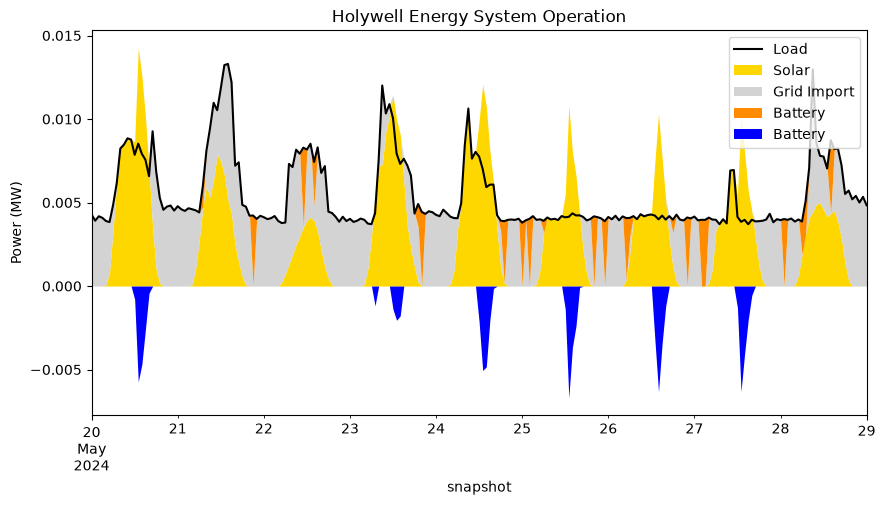

In [16]:
fig_start = pd.Timestamp(2024, 5, 20)
fig_end = pd.Timestamp(2024, 5, 29)

fig, ax = plt.subplots(figsize=(10, 5))

# plot load
ax = holywell_net.loads_t.p.sum(axis=1).loc[fig_start:fig_end].plot(label="Load", color="black")

# plot generation and storage as stacked area plots
pd.concat([
    holywell_net.generators_t.p.loc[fig_start:fig_end, "Solar"],
    holywell_net.links_t.p0.loc[fig_start:fig_end, "Grid Import"],
    holywell_net.storage_units_t.p_dispatch.loc[fig_start:fig_end, "Battery"],
    -holywell_net.storage_units_t.p_store.loc[fig_start:fig_end, "Battery"],
], axis=1).plot.area(ax=ax, stacked=True,
                     linewidth=0.0,
                      color=["gold", "lightgrey", "darkorange", "blue"],
                        label=["Solar", "Grid Import", "Battery Discharge", "Battery Charge"])


ax.set_ylabel("Power (MW)")
ax.set_title("Holywell Energy System Operation")
ax.legend(loc='upper right')
plt.show()

## Capacity Expansion

For a capacity expansion optimisation, we need to make some changes.
1. We need to make the generator and storage components extendable, so that the optimisation can choose how much capacity to install.
2. We need to set constraints on the maximum capacity that can be installed for the generator and storage components.
3. We need to set the investment cost of the generator and storage components to reflect the cost of installing additional capacity.

Edit your code above, making the following changes:
1. Set the p_nom_extendable parameter to True for the generator and storage components. You can remove the p_nom parameter for the generator and storage components, as the optimisation will determine the optimal capacity to install.
2. Set the p_nom_max parameter to the maximum capacity that can be installed for the generator and storage components. For example, if the maximum capacity of the solar PV system is 50 kW, set p_nom_max=0.05 for the generator component.
3. Set the capital_cost parameter to the investment cost of the generator and storage components. For example, if the capital cost of the solar PV system is £1000/kW, set capital_cost=1000 for the generator component. As we are only modelling over a single year, you can use a annualised capital cost calculated as follows:
$$ \text{annualised capital cost} = \frac{\text{capital cost}}{\text{lifetime}} \times \frac{1}{(1 + \text{discount rate})^{\text{lifetime}}}$$